# CSE 242 Assignment 2
**3 Questions, 100 pts**

**Your name: Kyle Saiki**

**Student ID: 2054582 **

> **Acknowledgment of AI assistance:** I used Claude (an AI assistant by Anthropic) to help write the code, the code comments, and the written explanations in this notebook.

## Instruction
Submit your assignments onto Canvas by the due date. Upload a zip file containing:

(1) The saved/latest .ipynb file.

(2) Also save your file into a pdf version, if error appears, save an html version instead (easy to grade for written questions).

(3) All other materials to make your .ipynb file runnable.

For assignment related questions, please reach TA or grader through EdDiscussion.

This is an individual assignment. All help from others (from the web, books other than text, genAI, or people other than the TA or instructor) must be clearly acknowledged.

Most coding parts can be finished with only 1-2 lines of codes.

Make sure you have installed required packages: scikit-learn.

Double click to edit each markdown cell.

## Objective
- Task 1: Maximum likelihood estiamtion (math)
- Task 2: Linear Regression (with Scikit-learn)
- Task 3: Principle Component Analysis (with Scikit-learn)

## Question 1 (Maximum likelihood estiamtion and Posterior, 20 pts)
Assume we have a coin that has some unknown probability $\theta$ of coming up heads (and probability $1-\theta$ of coming up tails). If the coin is flipped five times getting three heads and two tails ($D = \{H, H, H, T, T\}$) then:

**(a -- 10pts)** What is the maximum likelihood estimate for $\theta$?

**(b -- 10pts)** Assume that (before flipping the coin) we have a prior density $p(\theta)$ for the various values of $\theta$. Give the formula for the posterior probability density $p(\theta \mid D)$ as a function of the prior $p(\theta)$.

For Question 1(b), the solution is acceptable if the formula contains an integral.

**Solution (a):**

Each flip is an independent Bernoulli($\theta$) trial, so the likelihood of the data (3 heads, 2 tails) is

$$L(\theta) = P(D \mid \theta) = \theta^{3}(1-\theta)^{2}.$$

Maximize the log-likelihood instead (same maximizer, easier derivative):

$$\ell(\theta) = \log L(\theta) = 3\log\theta + 2\log(1-\theta)$$

$$\frac{d\ell}{d\theta} = \frac{3}{\theta} - \frac{2}{1-\theta} = 0 \;\;\Longrightarrow\;\; 3(1-\theta) = 2\theta \;\;\Longrightarrow\;\; \boxed{\hat{\theta}_{\text{MLE}} = \frac{3}{5} = 0.6}$$

This is a maximum because $\frac{d^{2}\ell}{d\theta^{2}} = -\frac{3}{\theta^{2}} - \frac{2}{(1-\theta)^{2}} < 0$ for every $\theta \in (0, 1)$. The MLE is simply the observed fraction of heads; multiplying the likelihood by the constant $\binom{5}{3}$ (if we only record the number of heads) would not change it.

**Solution (b):**

By Bayes' rule, the posterior is likelihood $\times$ prior, normalized by the evidence $P(D)$:

$$p(\theta \mid D) = \frac{P(D \mid \theta)\, p(\theta)}{P(D)} = \frac{\theta^{3}(1-\theta)^{2}\, p(\theta)}{\displaystyle\int_{0}^{1} t^{3}(1-t)^{2}\, p(t)\, dt}, \qquad 0 \le \theta \le 1.$$

The denominator does not depend on $\theta$; it only rescales the numerator so that the posterior integrates to 1 over $[0, 1]$.

*Special case:* with a conjugate prior $\theta \sim \text{Beta}(\alpha, \beta)$, the posterior is $\text{Beta}(\alpha + 3, \beta + 2)$; a uniform prior ($\alpha = \beta = 1$) gives $\text{Beta}(4, 3)$.

If you are not familair with Latex, you may attach a figure/screen-shoot and display the code below.

In [1]:
from IPython.display import Image
# Replace the figure name
# Image(filename='sample.png')

## Question 2 (Linear Regression, 40 pts)
In this question, you will be using Scikit-learn to empirically apply the Linear Regression model. We will adopt an advertisement dataset `Advertising.csv` from Kaggle.

### Reading data using Pandas

In [2]:
# Read the dataset you will be working on
# The dataframe loaded with pandas is named as data

import pandas as pd
data = pd.read_csv('Advertising.csv', index_col=0)  # Modify your data path accordingly.

# Take a look at the first 5 rows
data.head()

,TV,Radio,Newspaper,Sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


In [3]:
data.shape

(200, 4)

### Features and responses
**What are the features?**

- **TV:** advertising dollars spent on TV for a single product in a given market (in thousands of dollars)
- **Radio:** advertising dollars spent on Radio
- **Newspaper:** advertising dollars spent on Newspaper

**What is the response?**

- **Sales:** sales of a single product in a given market (in thousands of items)

**What else do we know?**

- There are 200 observations, and each observation (each row) is a single market.
- Your main task: predict the sales of a single product in a given market.
- Since the response variable is continuous, this is a regression problem.

### Linear regression
**Pros:** fast, no tuning required, highly interpretable

**Cons:** adopting the linear regression is unlikely to always generate the best predictive accuracy, since Linear Regression presumes a linear relationship between the features and response. This assumption may not always make sense. (But if one can transform the features so that do have a linear relationship, sometimes progress can be made, for example by taking logs.)

**Expression:**

$$y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_n x_n$$

- $y$: the response
- $\beta_0$: the intercept
- $\beta_1$: the coefficient for $x_1$ (the first feature)
- $\beta_i$ is the coefficient for $x_i$ (the ith feature, $1 \le i \le n$)

For this regression task:

$$y = \beta_0 + \beta_1 \times TV + \beta_2 \times Radio + \beta_3 \times Newspaper$$

The $\beta$ values ($\beta_0, \beta_1, \beta_2, \beta_3$) are called the model coefficients. These values are "learned" during the model fitting step using the "least squares" criterion. Then, we can make use of the fitted model to make predictions!

### Prepare the dataset for training use
- Scikit-learn expects X (feature matrix) and y (response vector) to be NumPy arrays.
- Pandas is built on top of NumPy, and exposes numpy methods. Thus, X can be a pandas DataFrame, y can be a pandas Series!

In [4]:
# Prepare the feature X
X = data[['TV', 'Radio', 'Newspaper']]

# check the type and shape of X
print(type(X))
print(X.shape)

<class 'pandas.DataFrame'>
(200, 3)


In [5]:
# Prepare the response Y
y = data['Sales']
# check the type and shape of y
print(type(y))
print(y.shape)

<class 'pandas.Series'>
(200,)


### Question 2.1 (Split the dataset into train and test parts, 5 pts)
For features $X$ and response $y$, use sklearn to perform the the splitting of dataset: $80\%$ for train data, $20\%$ for the test data.

In [6]:
################# Your answer for Question 2.1   #################
from sklearn.model_selection import train_test_split

# Split settings are constants so Q2.5 can reuse the exact same split
TEST_SIZE = 0.2     # 80% train / 20% test (sklearn's default would be 75/25)
RANDOM_STATE = 42   # fixed seed -> the same shuffle every run (reproducible)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
################# Your code above #################

Double check the shape of train and test data:

In [7]:
# default split is 80% for training and 20% for testing
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(160, 3)
(160,)
(40, 3)
(40,)


### Question 2.2 (Train a Linear regression model via Scikit-learn, 10 pts)
Assume you model is named as `model`, and you train the linear regression model to fit on the training data.

In [8]:
################# Your answer for Question 2.2   #################
# Name your linear regression model as 'model', so proceeding cells won't run into errors.
from sklearn.linear_model import LinearRegression

# Ordinary least squares: learns the intercept and one coefficient per
# feature, using the training data only (the test set stays unseen)
model = LinearRegression().fit(X_train, y_train)
################# Your code above #################

In [9]:
# Take a look at your model coefficients
import numpy as np
print(np.round(model.intercept_, 4))
print([np.round(val, 4) for val in model.coef_])

2.9791
[np.float64(0.0447), np.float64(0.1892), np.float64(0.0028)]


In [10]:
# Match the feature names with the trained coefficients
list(zip(data.columns[:3].tolist(), model.coef_))

[('TV', np.float64(0.044729517468716326)),
 ('Radio', np.float64(0.1891950542343766)),
 ('Newspaper', np.float64(0.0027611143413672056))]

### Question 2.3 (Interpreting model coefficients, 10 pts)
The coefficients of each feature are printed above.

**Your tasks:**

1. What is the trained linear regression model? (replace $\beta_i$ below with the trained coefficients, reserve four decimal places, 5 pts)

$$y = \beta_0 + \beta_1 \times TV + \beta_2 \times Radio + \beta_3 \times Newspaper$$

2. (Open) question (5 pts): how do you interpret the coefficient of TV ($\beta_1$)?

**Your solution for Question 2.3:**

**Trained model** (coefficients rounded to four decimal places):

$$\widehat{\text{Sales}} = 2.9791 + 0.0447 \times \text{TV} + 0.1892 \times \text{Radio} + 0.0028 \times \text{Newspaper}$$

**Interpreting $\beta_1 = 0.0447$ (TV):** holding Radio and Newspaper spending fixed, each additional \$1,000 spent on TV advertising is associated with about 0.0447 thousand, i.e. roughly 45, more units sold (an extra \$10,000 on TV $\approx$ 447 more units). Two caveats: this is an *association* learned from observational data, not proof that TV ads cause the extra sales, and it is only reliable within the range of budgets seen in the data (TV spending from \$0.7k to \$296.4k).

### Making predictions

In [11]:
# make predictions on the testing set
y_pred = model.predict(X_test)

In [12]:
# Print the test accuracy score from your trained linear regression model
model.score(X_test,y_test)

0.899438024100912

### Model evaluation metrics for regression
Evaluation metrics for classification problems, such as accuracy, are not useful for regression problems. Instead, we need evaluation metrics designed for comparing continuous values. (Since predictions would hardly ever exactly match the measured quantities.)

**Mean Squared Error (MSE)** is the mean of the squared errors:

$$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2$$

**Root Mean Squared Error (RMSE)** is a popular evaluation metric for regression, which is defined as the square root of the mean of the squared errors:

$$\text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}$$

### Question 2.4 (Evaluate your predictions on test features with RMSE metric, 5 pts)
Hint: you may calculate MSE using scikit-learn, but RMSE is a little bit different from MSE.

In [13]:
from sklearn import metrics
################# Your answer for Question 2.4   #################
# MSE averages the squared errors; its square root (RMSE) is back in the
# units of Sales (thousands of items), which makes it easier to interpret
mse = metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)  # sklearn >= 1.4 also has metrics.root_mean_squared_error

print(f'Test MSE:  {mse:.4f}')
print(f'Test RMSE: {rmse:.4f}')
################# Your code above #################

Test MSE:  3.1741
Test RMSE: 1.7816


### Question 2.5 (Does the feature 'Newspaper' help? 10 pts)
Does the feature `Newspaper` contribute or impair the model prediction? Now repeat previous procedure:

1. For features $X$, only select TV and Radio; response $y$ is unchanged.
2. Split the dataset as what you have done before.
3. Fit/Train the model on the train data.
4. Make predictions on the test data.
5. Compute the RMSE of the predictions on the test data.
6. Show your observations!

**Reminder:** if you use `random_state` while splitting the dataset, make sure the value of `random_state` is the same for the two splits. So that the test data only differs in the column of `Newspaper`.

In [14]:
################# Your answer for Question 2.5   #################
# 1. Features: TV and Radio only (response y is unchanged)
X_tv_radio = data[['TV', 'Radio']]

# 2. Same split settings as Q2.1, so only the Newspaper column differs
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_tv_radio, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
assert X2_test.index.equals(X_test.index)  # same 40 test markets as Q2.1

# 3. Fit a new model on the training data
model2 = LinearRegression().fit(X2_train, y2_train)

# 4. Predict on the test data
y2_pred = model2.predict(X2_test)

# 5. Test RMSE, side by side with the 3-feature model from Q2.4
rmse2 = np.sqrt(metrics.mean_squared_error(y2_test, y2_pred))
print(f'Test RMSE, TV + Radio + Newspaper: {rmse:.4f}')
print(f'Test RMSE, TV + Radio:             {rmse2:.4f}')
################# Your code above #################

Test RMSE, TV + Radio + Newspaper: 1.7816
Test RMSE, TV + Radio:             1.7714


*Extra check (optional):* a single 40-market test set is a small, noisy yardstick, so I also compare both feature sets with 10-fold cross-validation, where every market is used for testing exactly once.

In [15]:
from sklearn.model_selection import KFold, cross_val_score

# Shuffled 10-fold CV; the same folds are used for both feature sets
cv = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
for features in (['TV', 'Radio', 'Newspaper'], ['TV', 'Radio']):
    # sklearn maximizes scores, so it reports RMSE as a negative number
    scores = cross_val_score(LinearRegression(), data[features], y, cv=cv,
                             scoring='neg_root_mean_squared_error')
    label = ' + '.join(features) + ':'
    print(f'10-fold CV RMSE, {label:<23} {-scores.mean():.4f}')

10-fold CV RMSE, TV + Radio + Newspaper: 1.6842
10-fold CV RMSE, TV + Radio:             1.6745


**Your observations:**

- **Newspaper does not help; removing it slightly *improves* the predictions.** Test RMSE drops from **1.7816** (TV + Radio + Newspaper) to **1.7714** (TV + Radio).
- **Why:** Newspaper's coefficient is tiny (0.0028, about 3 extra units per \$1,000, versus about 45 for TV and 189 for Radio), so once TV and Radio are known it adds almost no information. An extra, uninformative feature mainly lets the model fit a little more noise in the training data, which costs a bit of accuracy on unseen markets.
- **Is the gap real?** It is small (about 0.01), and one 40-market test set is noisy, but 10-fold cross-validation points the same way: **1.6842** with Newspaper versus **1.6745** without.
- **Conclusion:** prefer the simpler TV + Radio model. It predicts at least as well, with one fewer input to collect and interpret.

## Question 3 (PCA, 40 pts)
In this question, we will explore how PCA helps with reducing the dimensionality through scikit-learn. We will adopt a simple digits dataset contained in scikit-learn.

In [16]:
# import libraries
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns;
sns.set()
from sklearn.datasets import load_digits
data_digit = load_digits()
data_digit.data.shape

(1797, 64)

As you have seen above, there are 1797 rows and 64 columns in this dataset. Each row denotes the pixel values of an image. Since each image is 8*8 (in pixel), the dimension of each feature is 64. Let's take a look at a few images contained in this dataset.

In [17]:
# A help function to display images with labels
def display_digits(imgs):
    h = 3
    w = 5
    fig, axes = plt.subplots(h, w)
    for i in range(h):
        for j in range(w):
            if imgs.shape[1] == 64:
                axes[i, j].imshow(imgs[i * w + j].reshape(8, 8))
            else:
                axes[i, j].imshow(imgs[i * w + j])
            axes[i, j].axis('off')
            axes[i, j].set_title(f'label {data_digit.target[i * w + j]}')

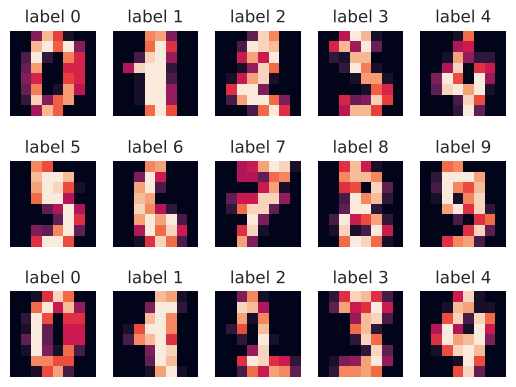

In [18]:
# Take a look at a few examples
display_digits(data_digit.images)

PCA finds uncorrelated orthogonal axes (principal components) in a high dimensional space (i.e., 64) to project the feature onto principal components.

### Question 3.1 (PCA and dimensionality deduction with Scikit-learn, 10 pts)
In this question, you may use the implementation of PCA from scikit-learn, as imported below. Detailed explanations of parameters settings are available in [this link](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).

**Your task in this question:**

- Fit the model with feature X (`data_digit.data` for this dataset) and apply the dimensionality reduction on X, keep 2 components.

In [19]:
from sklearn.decomposition import PCA

################# Your answer for Question 3.1   #################
# Learn the 2 directions of largest variance from the 64 pixel features,
# then project every image onto them (fit + transform in one step)
pca_2d = PCA(n_components=2)

# name the transformed (dimension reduced) feature as projected
projected = pca_2d.fit_transform(data_digit.data)
################# Complete the code above #################


# The code below checks whether the feature dimension 64 is reduced to 2.
print(data_digit.data.shape)
print(projected.shape)

(1797, 64)
(1797, 2)


With the reduced dimension of features, we can now visualize the projected/reduced features in a 2-dimension plot as below. There are hardly any overlaps between digit 0 and any other digits. While in the central area of the figure, features are not well separable.

<Figure size 1800x800 with 0 Axes>

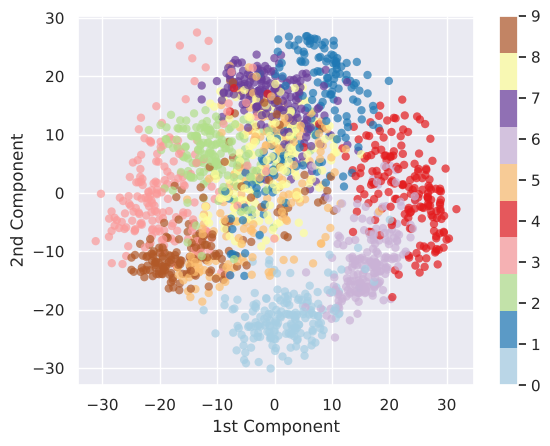

<Figure size 1800x800 with 0 Axes>

In [20]:
# (changed) plt.cm.get_cmap was removed in Matplotlib 3.9;
# plt.get_cmap does the same job and works in old and new versions
plt.scatter(projected[:, 0], projected[:, 1],
            c=data_digit.target, edgecolor='none', alpha=0.7,
            cmap=plt.get_cmap('Paired', 10))
plt.xlabel('1st Component')
plt.ylabel('2nd Component')
plt.colorbar()
plt.figure(figsize=(18, 8))

### Question 3.2 (How many components do we need? 15 pts)
In practice, suppose you are given a high-dimension dataset, and you are interested in performing a dimension reduciton with PCA. How many conponents do we need? One method is to look at the distribution of the explained variance ratio w.r.t. each component.

In this question, you may use the function `explained_variance_ratio_` in pca (with scikit-learn) to address this question. Detailed explanations of parameters settings are available in [this link](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).

**Your task in this question:**

1. Print the ratio of variance explained by each of the selected components;
2. Visualize with matplotlib or seaborn (x axis: $i$-th component; y axis: the corresponding ratio of explained variance).

[0.1489 0.1362 0.1179 0.0841 0.0578 0.0492 0.0432 0.0366 0.0335 0.0308
 0.0237 0.0227 0.0182 0.0177 0.0147 0.0141 0.0132 0.0125 0.0102 0.0091
 0.0089 0.008  0.0077 0.0072 0.007  0.006  0.0058 0.0052 0.0049 0.0043
 0.0037 0.0035 0.0034 0.0033 0.0031 0.0029 0.0026 0.0023 0.0022 0.0021
 0.0019 0.0016 0.0015 0.0014 0.0012 0.0011 0.001  0.0008 0.0006 0.0004
 0.0002 0.0001 0.0001 0.0001 0.     0.     0.     0.     0.     0.
 0.     0.     0.     0.    ]
80% of the variance -> first 13 components
90% of the variance -> first 21 components
95% of the variance -> first 29 components


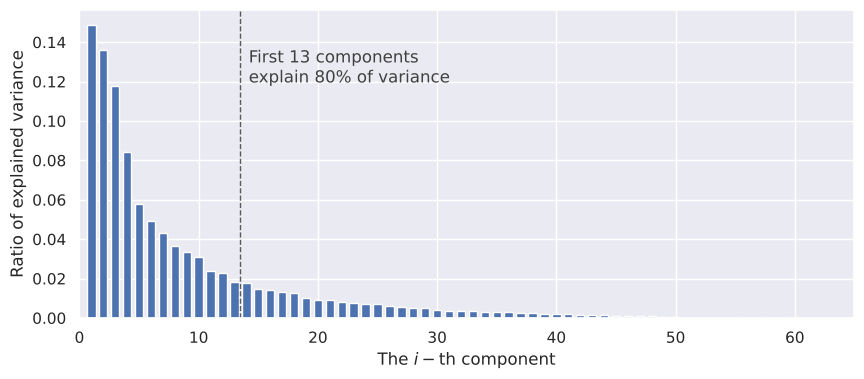

In [21]:
################# Your answer for Question 3.2   #################
# Keep all 64 components to see how the total variance is spread across them
pca_full = PCA().fit(data_digit.data)
ratios = pca_full.explained_variance_ratio_  # sorted high -> low, sums to 1

# 1. Ratio of variance explained by each component
with np.printoptions(precision=4, suppress=True):
    print(ratios)

# Fewest components whose cumulative ratio reaches each target
cumulative = np.cumsum(ratios)
targets = (0.80, 0.90, 0.95)
n_needed = {t: int(np.searchsorted(cumulative, t)) + 1 for t in targets}
for t, k in n_needed.items():
    print(f'{t:.0%} of the variance -> first {k} components')

# 2. Scree plot: one bar per component (numbered from 1); the dashed
#    line marks where the cumulative explained variance reaches 80%
components = np.arange(1, len(ratios) + 1)
k80 = n_needed[0.80]
plt.figure(figsize=(10, 4))
plt.bar(components, ratios, width=0.7)
plt.axvline(k80 + 0.5, color='0.35', linestyle='--', linewidth=1)
plt.text(k80 + 1.2, ratios.max() * 0.92,
         f'First {k80} components\nexplain 80% of variance',
         color='0.25', va='top')
plt.xlim(0, len(ratios) + 1)
plt.xlabel('The $i-$th component')
plt.ylabel('Ratio of explained variance')
plt.show()
################# Complete the code above #################

**Observation for Question 3.2:** the ratios fall off quickly. The first two components (the scatter plot above) explain only about 28.5% of the variance, but 13 components explain 80%, 21 explain 90% and 29 explain 95%, while the last components explain almost nothing. So for this dataset roughly 13 to 30 of the 64 components are enough, depending on how much variance we need to keep.

### How to obtain eigen values and vectors from sklearn PCA
- Eigen values -- `your-PCA-model.explained_variance_`
- Eigen vectors -- `your-PCA-model.components_`

### Eigen vectors (Eigen digits)

Text(0.5, 0.98, 'The eigen vector of each component')

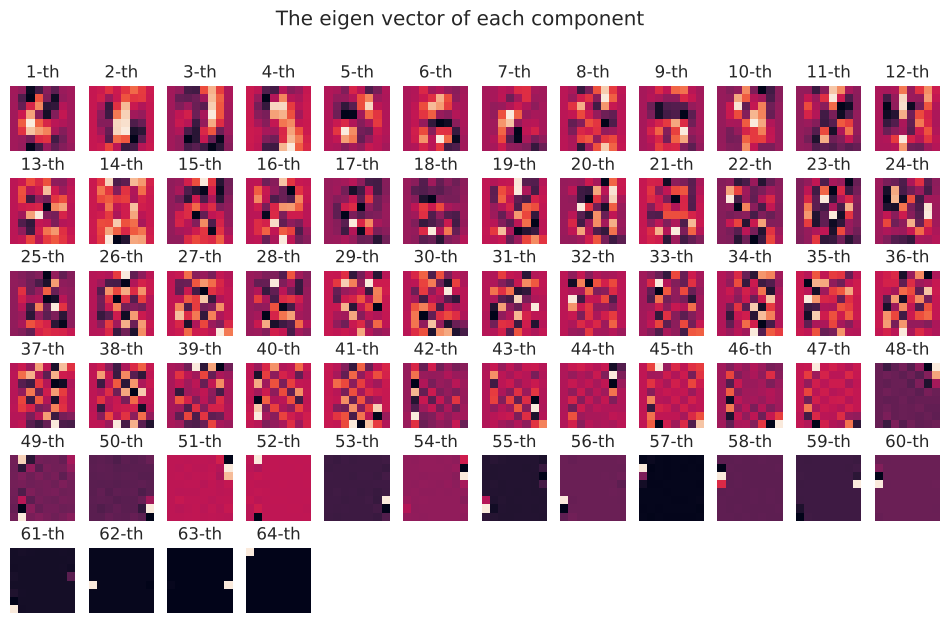

In [22]:
# Default # of components is the dimension of feature space
pca = PCA()
pca.fit(data_digit.data)
h = 6
w = 12
fig, axes = plt.subplots(h, w)
fig.set_size_inches(12, 7)
for i in range(h):
    for j in range(w):
        idx = i * w + j
        if idx > 63:
            axes[i, j].axis('off')
        else:
            axes[i, j].imshow(pca.components_[idx].reshape(8, 8))
            axes[i, j].axis('off')
            axes[i, j].set_title(f'{idx + 1}-th')
fig.suptitle('The eigen vector of each component')

### Question 3.3 What are your observations from the visualized eigen vectors? (5 pts)

**Your solutions for Question 3.3:**

- **The first components look like blurry pieces of digits.** Components 1 to about 10 are smooth, large-scale patterns in the center of the image (vertical strokes, loops, diagonal bars). That is where pixel values differ most from one digit to another, so these directions capture the most variance (the first 13 explain 80%, see Question 3.2), while the image border gets almost no weight.
- **Middle components encode fine detail.** As the index grows, the patterns become finer, checkerboard-like and hard to interpret: small stroke variations and pixel-level noise, each worth little variance.
- **The last components are nearly blank.** From about the 48th on, each tile is flat except for one or two pixels on the image border, i.e. pixels that are almost always 0, and each of these components explains less than 0.1% of the variance. The final three single out the three pixels that are 0 in every image, so their eigenvalues are 0: they carry no information and can be dropped with no loss.
- **Colors are relative.** An eigenvector is only defined up to its sign, and each tile has its own color scale, so light and dark regions could be swapped without changing the meaning.

### Feature reconstruction:
Suppose you only want to preserve $80\%$ variance after applying PCA for the dimension reduction, due to storage issues, etc.

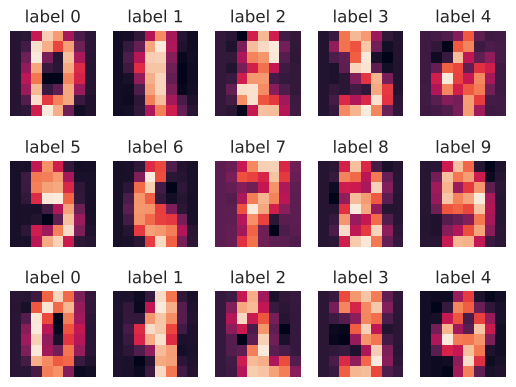

In [23]:
# Use pca from sklearn to fit on the feature space
pca_08 = PCA(0.8).fit(data_digit.data)

# Reconstruct
lower_dimension = pca_08.fit_transform(data_digit.data)
reconstructed = pca_08.inverse_transform(lower_dimension)

# Display the reconstructed images (with a much lower dimension)
display_digits(reconstructed)

Assume now you are given only a set of perturbed images (with some random noise). As shown below, the figures become much more difficult to recognize.

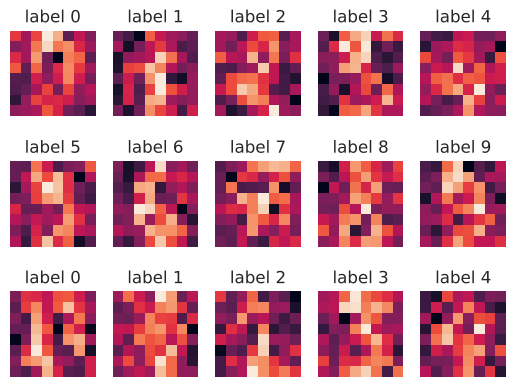

In [24]:
# (added) fixed seed: the same noise, and the same numbers below, on every run
np.random.seed(0)

# Apply random noise on clean images
noisy_imgs = np.random.normal(data_digit.data, 5)
# Display the noisy images
display_digits(noisy_imgs)

### Question 3.4 Does PCA mitigate the random noise? (10 pts)
**Your tasks:**

- Perform feature reconstruction on `noisy_imgs` (preserving $80\%$ variance after applying PCA for the dimension reduction)
- Explain your understandings on why PCA reconstructs cleaner images.

Components kept: 41 of 64
MSE vs clean images: noisy = 24.87, reconstructed = 17.67


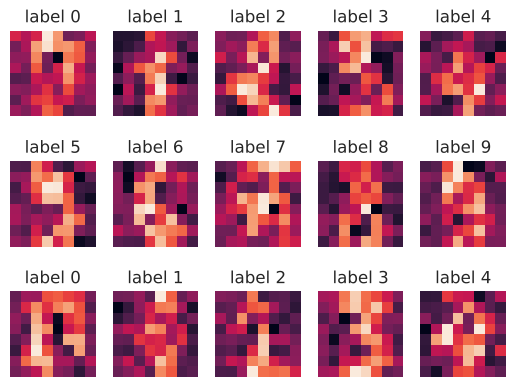

In [25]:
################# Your answer for Question 3.4   #################
# Only the noisy images are available, so fit PCA on them and keep the
# fewest components that explain 80% of their variance
pca_noisy = PCA(0.8).fit(noisy_imgs)
print(f'Components kept: {pca_noisy.n_components_} of {noisy_imgs.shape[1]}')

# Project onto the kept components, then map back to the 64 pixels; the
# discarded low-variance directions (mostly noise) are left out
lower_dim_noisy = pca_noisy.transform(noisy_imgs)

# name the reconstructed images from noisy images as 'reconstructed_noise'
reconstructed_noise = pca_noisy.inverse_transform(lower_dim_noisy)

# Effect: mean squared error vs. the clean images (lower = cleaner)
mse_noisy = np.mean((noisy_imgs - data_digit.data) ** 2)
mse_recon = np.mean((reconstructed_noise - data_digit.data) ** 2)
print(f'MSE vs clean images: noisy = {mse_noisy:.2f}, '
      f'reconstructed = {mse_recon:.2f}')

# Display the reconstructed images
display_digits(reconstructed_noise)
################# Complete the code above #################

*Extra check (optional):* how much of the noisy data's variance is noise, and what a stricter threshold (50% of the variance) does.

Total variance: clean = 1202, noisy = 2778
50% variance: 16 components, MSE vs clean = 9.69


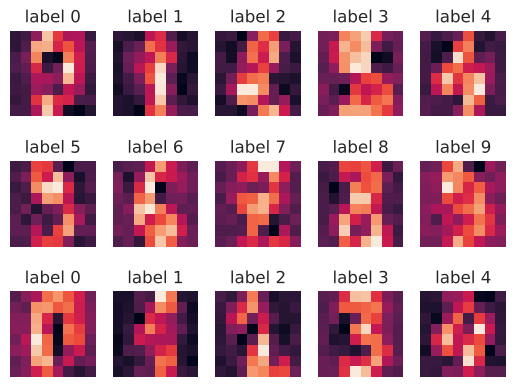

In [26]:
# Noise adds 5**2 = 25 variance to each of the 64 pixels (about 1600 in total)
total_var_clean = data_digit.data.var(axis=0, ddof=1).sum()
total_var_noisy = noisy_imgs.var(axis=0, ddof=1).sum()
print(f'Total variance: clean = {total_var_clean:.0f}, '
      f'noisy = {total_var_noisy:.0f}')

# Fewer components -> more noise removed, at the cost of some fine detail
pca_noisy_50 = PCA(0.5).fit(noisy_imgs)
reconstructed_50 = pca_noisy_50.inverse_transform(
    pca_noisy_50.transform(noisy_imgs))
mse_50 = np.mean((reconstructed_50 - data_digit.data) ** 2)
print(f'50% variance: {pca_noisy_50.n_components_} components, '
      f'MSE vs clean = {mse_50:.2f}')
display_digits(reconstructed_50)

**Your written answers for Question 3.4:**

**Yes, PCA reduces the noise, though at the 80% setting only partially.** Keeping 80% of the variance retains 41 of the 64 components, and the mean squared error against the clean images falls from about 24.9 to about 17.7. The digits look smoother but are still grainy; with a stricter 50% threshold (16 components, extra check above) the error falls to about 9.7 and the digits become clearly readable.

**Why PCA reconstructs cleaner images:**

1. **The signal is concentrated; the noise is spread out.** Neighboring pixels of a digit are strongly correlated, so the digit structure lives in a few high-variance directions (13 components already hold 80% of the clean data's variance). The added Gaussian noise is independent for every pixel, so its variance ($\sigma^2 = 25$) is spread *evenly* over all 64 directions.
2. **Reconstruction keeps only the top directions.** `transform` projects each image onto the kept components and `inverse_transform` rebuilds it from those components alone. Most of the signal survives, while the noise in the discarded directions is thrown away (only about $k/64$ of the noise is kept). PCA acts as a filter that keeps the dominant shared patterns and drops the rest.
3. **Why 80% still leaves visible noise here.** The noise is strong ($\sigma = 5$ on pixel values of 0 to 16): it adds about $64 \times 25 = 1600$ units of variance, more than the clean data's total of about 1202. Since over half of the variance in `noisy_imgs` is noise, keeping 80% of it forces PCA to keep many noise-dominated components (41), so roughly $41/64$ of the noise survives. Choosing $k$ is a trade-off: fewer components remove more noise but also blur fine stroke details.